# Notebook 01: Exploratory Data Analysis (EDA) & Market Coverage

**Mandi Watch Project**  
This notebook conducts comprehensive exploratory analysis of the cleaned and aggregated weekly Agmarknet data across 8 target commodities and 3 top states (Uttar Pradesh, Madhya Pradesh, Maharashtra).

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from src.config import load_config

config = load_config()
weekly_path = ROOT / "data" / "processed" / "weekly.parquet"
df_weekly = pd.read_parquet(weekly_path)
df_weekly["series_id"] = df_weekly["market"] + "_" + df_weekly["commodity"]
print(f"Loaded weekly dataset: {df_weekly.shape[0]:,} rows across {df_weekly['series_id'].nunique():,} unique series.")

Loaded weekly dataset: 410,230 rows across 955 unique series.


### 1. Dataset Overview & Schema Inspection

In [2]:
display(df_weekly.head())
print("\n--- Data Types & Non-Null Counts ---")
print(df_weekly.info())

,week_start,iso_year,iso_week,state,district,market,commodity,variety,grade,median_price,n_reports,min_price,max_price,std_price,flat_run_share,commodity_code,log_price,log_price_interpolated,is_interpolated,series_id
0,2019-09-16,2019,38,Uttar Pradesh,Auraiya,Achalda,Brinjal,Round/Long,FAQ,1150.0,3.0,1100.0,1250.0,76.376262,0.0,35,7.047517,7.047517,False,Achalda_Brinjal
1,2019-09-23,2019,39,Uttar Pradesh,Auraiya,Achalda,Brinjal,Round/Long,FAQ,1200.0,6.0,1100.0,1300.0,66.458007,0.0,35,7.090077,7.090077,False,Achalda_Brinjal
2,2019-09-30,2019,40,Uttar Pradesh,Auraiya,Achalda,Brinjal,Round/Long,FAQ,1100.0,5.0,1100.0,1240.0,62.609903,0.0,35,7.003065,7.003065,False,Achalda_Brinjal
3,2019-10-07,2019,41,Uttar Pradesh,Auraiya,Achalda,Brinjal,Round/Long,FAQ,1300.0,6.0,1200.0,2000.0,300.693643,0.0,35,7.170120,7.170120,False,Achalda_Brinjal
4,2019-10-14,2019,42,Uttar Pradesh,Auraiya,Achalda,Brinjal,Round/Long,FAQ,1945.0,6.0,1800.0,2050.0,86.023253,0.0,35,7.573017,7.573017,False,Achalda_Brinjal



--- Data Types & Non-Null Counts ---


<class 'pandas.DataFrame'>
RangeIndex: 410230 entries, 0 to 410229
Data columns (total 20 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   week_start              410230 non-null  object 
 1   iso_year                410230 non-null  int64  
 2   iso_week                410230 non-null  int64  
 3   state                   410230 non-null  str    
 4   district                410230 non-null  str    
 5   market                  410230 non-null  str    
 6   commodity               410230 non-null  str    
 7   variety                 410230 non-null  str    
 8   grade                   410230 non-null  str    
 9   median_price            354712 non-null  float64
 10  n_reports               354712 non-null  float64
 11  min_price               354712 non-null  float64
 12  max_price               354712 non-null  float64
 13  std_price               336393 non-null  float64
 14  flat_run_share          354712 

### 2. Series Distribution by State & Commodity

In [3]:
series_summary = df_weekly.groupby(["state", "commodity"])["series_id"].nunique().unstack(fill_value=0)
print("Active Series Count by State and Commodity:")
display(series_summary)

Active Series Count by State and Commodity:


commodity,Brinjal,Cauliflower,Green Chilli,Onion,Paddy (Dhan)(Common),Potato,Tomato,Wheat
state,,,,,,,,
Madhya Pradesh,0,10,21,2,8,6,13,0
Maharashtra,0,0,0,10,0,0,0,0
Uttar Pradesh,93,67,171,166,23,129,80,156


### 3. Price Distributions across Commodities (INR / quintal)

C:\Users\DELL\AppData\Local\Temp\ipykernel_21488\2222189759.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=valid_prices, x="commodity", y="median_price", palette="Set2")


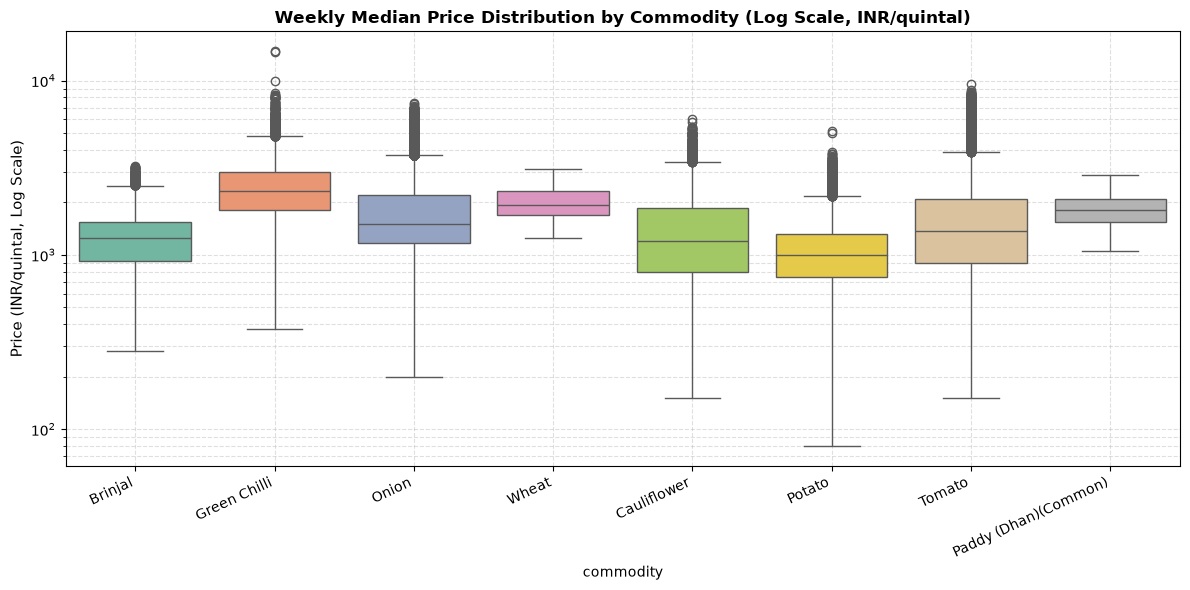

In [4]:
plt.figure(figsize=(12, 6))
valid_prices = df_weekly[df_weekly["median_price"].notna()]
sns.boxplot(data=valid_prices, x="commodity", y="median_price", palette="Set2")
plt.yscale("log")
plt.xticks(rotation=25, ha="right", fontsize=10)
plt.title("Weekly Median Price Distribution by Commodity (Log Scale, INR/quintal)", fontsize=12, fontweight="bold")
plt.ylabel("Price (INR/quintal, Log Scale)", fontsize=11)
plt.grid(True, which="both", ls="--", alpha=0.4)
plt.tight_layout()
plt.show()

### 4. Annual Reporting Dynamics & Temporal Coverage

commodity,Brinjal,Cauliflower,Green Chilli,Onion,Paddy (Dhan)(Common),Potato,Tomato,Wheat
iso_year,,,,,,,,
2015,838,658,1393,3847,352,1939,981,4358
2016,844,612,1366,3561,434,1699,946,3941
2017,1517,1122,3524,4790,618,2728,1477,5627
2018,2415,2035,6179,6643,725,3875,2516,6857
2019,3068,2679,7770,6804,846,4547,3305,7209
2020,3718,2956,8238,8096,649,5685,3462,7048
2021,4028,3086,8555,8485,685,6076,3890,7103
2022,4034,3000,8915,8673,1169,6167,4019,7355
2023,3969,3054,8588,8432,1392,6072,3825,7257


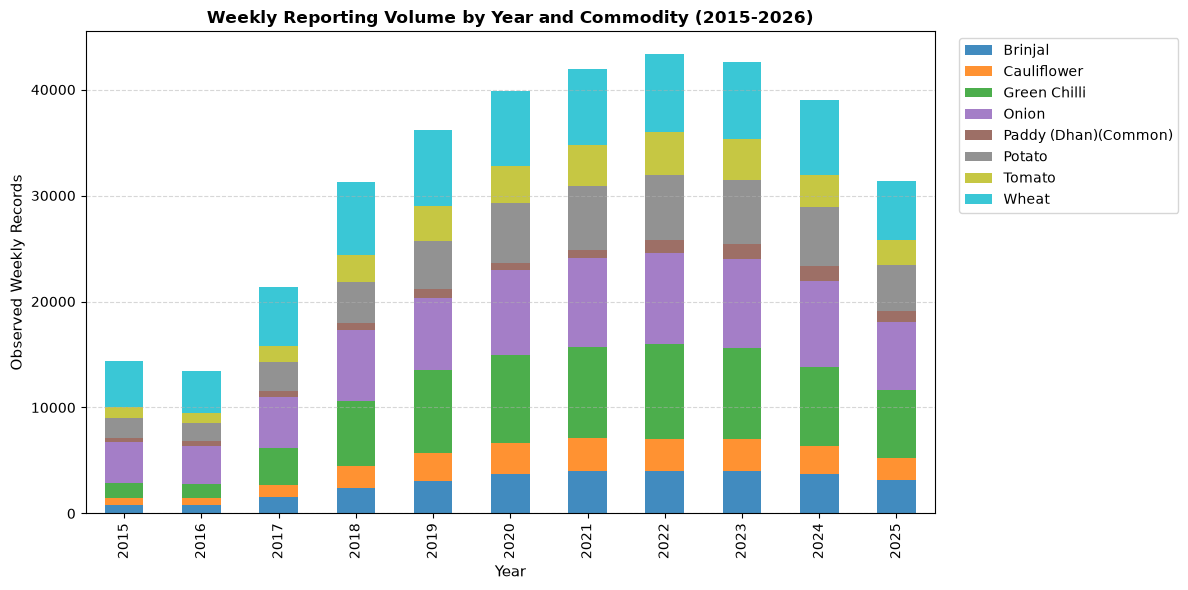

In [5]:
yearly_counts = valid_prices.groupby(["iso_year", "commodity"]).size().unstack(fill_value=0)
display(yearly_counts)

yearly_counts.plot(kind="bar", stacked=True, figsize=(12, 6), colormap="tab10", alpha=0.85)
plt.title("Weekly Reporting Volume by Year and Commodity (2015-2026)", fontsize=12, fontweight="bold")
plt.xlabel("Year", fontsize=11)
plt.ylabel("Observed Weekly Records", fontsize=11)
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

### 5. Flat-Run and Interpolation Diagnosis

In [6]:
flat_run_share = (df_weekly["flat_run_share"] > 0.5).mean() * 100
interp_share = df_weekly["is_interpolated"].mean() * 100
print(f"Share of weekly records with >=50% flat-run days: {flat_run_share:.2f}%")
print(f"Share of weekly records linearly interpolated (gap <= 2 weeks): {interp_share:.2f}%")

Share of weekly records with >=50% flat-run days: 7.89%
Share of weekly records linearly interpolated (gap <= 2 weeks): 2.05%
